# 🛒 Shopper Spectrum: Customer Segmentation & Product Recommendations

**Domain:** E-Commerce and Retail Analytics

This notebook builds:
1. A cleaned transaction dataset from the UK Online Retail data
2. Exploratory Data Analysis (EDA) of purchase behavior
3. RFM (Recency, Frequency, Monetary) features and a KMeans customer segmentation model
4. An item-based collaborative filtering product recommendation engine

All trained artifacts are saved to disk for use by the companion **Streamlit app**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
import pickle
import json
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

DATA_PATH = 'online_retail.csv'  # place the dataset in the same folder as this notebook

## Step 1: Dataset Collection and Understanding

The dataset contains e-commerce transactions with columns: `InvoiceNo`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, `Country`.

In [2]:
df = pd.read_csv(DATA_PATH, encoding='latin1')
print("Shape:", df.shape)
df.head()

Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2022-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2022-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2022-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [4]:
print("Missing values per column:")
print(df.isna().sum())
print()
print("Duplicate rows:", df.duplicated().sum())
print("Cancelled invoices (InvoiceNo starts with 'C'):", df['InvoiceNo'].astype(str).str.startswith('C').sum())
print("Non-positive Quantity:", (df['Quantity'] <= 0).sum())
print("Non-positive UnitPrice:", (df['UnitPrice'] <= 0).sum())
print("Unique customers:", df['CustomerID'].nunique())
print("Unique countries:", df['Country'].nunique())

Missing values per column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268
Cancelled invoices (InvoiceNo starts with 'C'): 9288
Non-positive Quantity: 10624
Non-positive UnitPrice: 2517
Unique customers: 4372
Unique countries: 38


## Step 2: Data Preprocessing

- Remove rows with missing `CustomerID`
- Exclude cancelled invoices (`InvoiceNo` starting with `'C'`)
- Remove non-positive quantities and prices
- Drop rows with missing product descriptions and exact duplicate rows

In [5]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df = df.dropna(subset=['CustomerID'])
print("After dropping missing CustomerID:", df.shape)

df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.startswith('C')]
print("After excluding cancellations:", df.shape)

df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
print("After removing non-positive qty/price:", df.shape)

df = df.dropna(subset=['Description'])
df['Description'] = df['Description'].str.strip()
print("After dropping missing description:", df.shape)

before = df.shape[0]
df = df.drop_duplicates()
print(f"Dropped {before - df.shape[0]} exact duplicate rows")

df['CustomerID'] = df['CustomerID'].astype(int)
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# Use the most frequent description text per StockCode (some codes have multiple/typo'd descriptions)
desc_map = df.groupby('StockCode')['Description'].agg(lambda x: x.value_counts().idxmax())
df['Description'] = df['StockCode'].map(desc_map)

print("Final cleaned shape:", df.shape)
df.head()

After dropping missing CustomerID: (406829, 8)
After excluding cancellations: (397924, 8)
After removing non-positive qty/price: (397884, 8)
After dropping missing description: (397884, 8)
Dropped 5192 exact duplicate rows
Final cleaned shape: (392692, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2022-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2022-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2022-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2022-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2022-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## Step 3: Exploratory Data Analysis (EDA)

### 3.1 Transaction volume by country

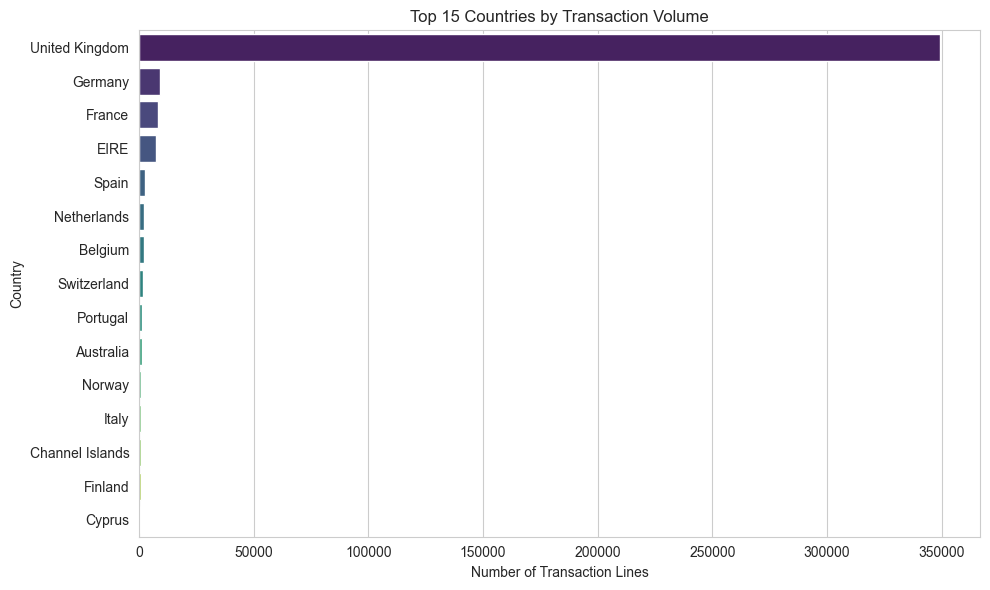

In [7]:
from pathlib import Path

country_counts = df['Country'].value_counts().head(15)
plt.figure(figsize=(10,6))
sns.barplot(x=country_counts.values, y=country_counts.index, palette='viridis')
plt.title('Top 15 Countries by Transaction Volume')
plt.xlabel('Number of Transaction Lines')
plt.ylabel('Country')
plt.tight_layout()
Path('figs').mkdir(parents=True, exist_ok=True)
plt.savefig('figs/country_volume.png', dpi=110)
plt.show()

### 3.2 Top-selling products

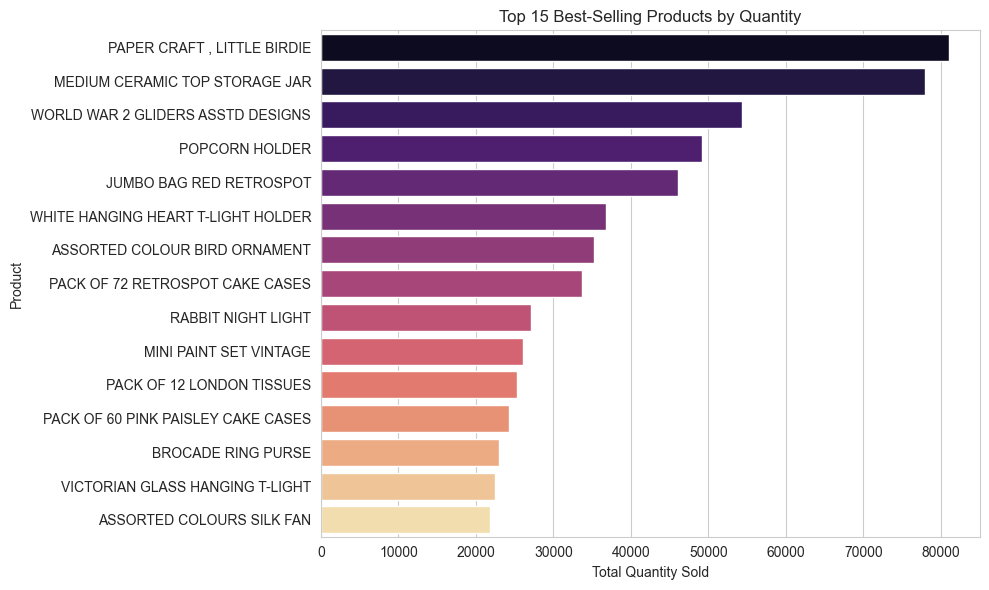

In [8]:
top_products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(15)
plt.figure(figsize=(10,6))
sns.barplot(x=top_products.values, y=top_products.index, palette='magma')
plt.title('Top 15 Best-Selling Products by Quantity')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product')
plt.tight_layout()
plt.savefig('figs/top_products.png', dpi=110)
plt.show()

### 3.3 Purchase trends over time

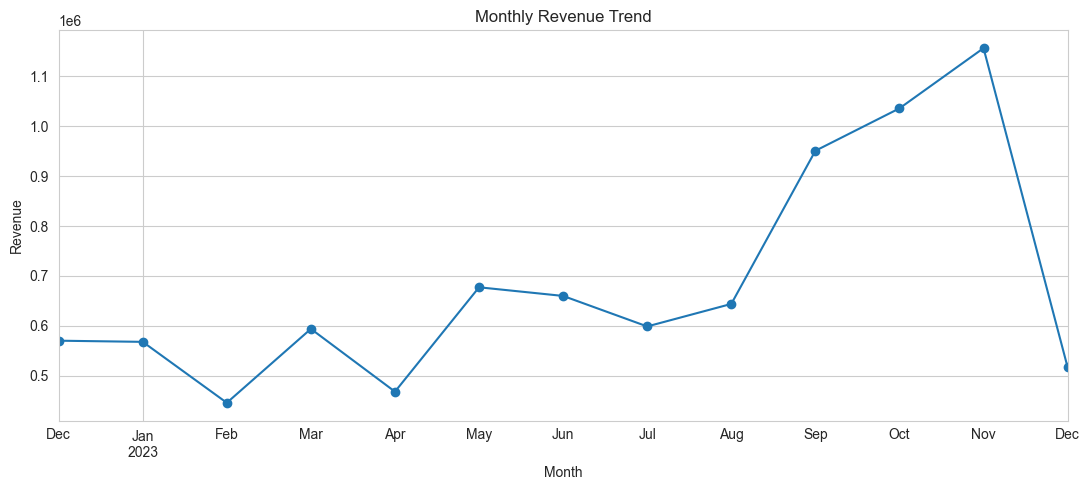

In [9]:
monthly = df.set_index('InvoiceDate').resample('ME')['TotalPrice'].sum()
plt.figure(figsize=(11,5))
monthly.plot(marker='o')
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.tight_layout()
plt.savefig('figs/monthly_trend.png', dpi=110)
plt.show()

### 3.4 Monetary distribution per transaction and per customer

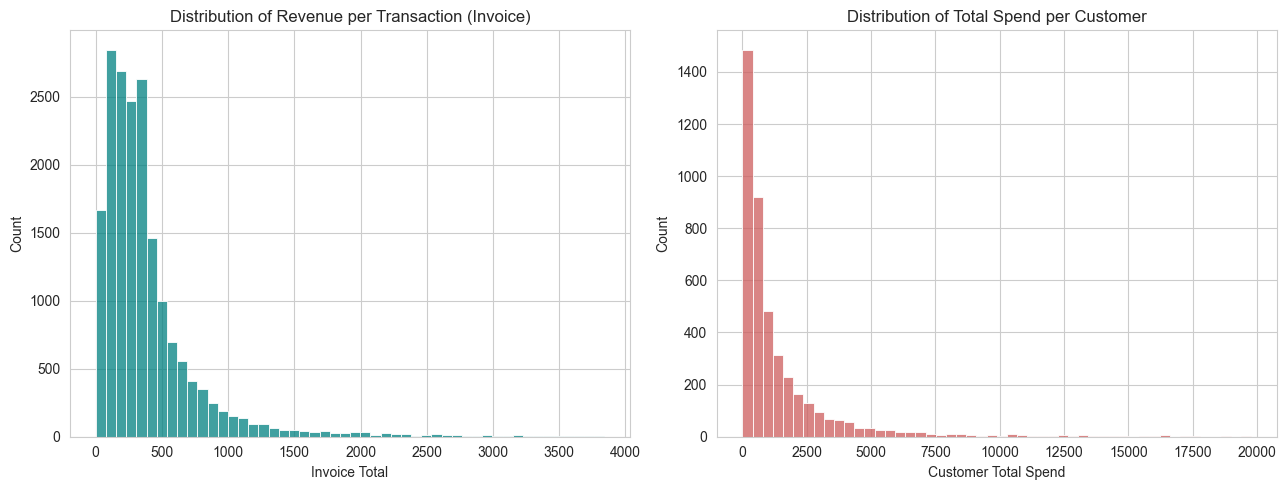

In [10]:
invoice_totals = df.groupby('InvoiceNo')['TotalPrice'].sum()
customer_totals = df.groupby('CustomerID')['TotalPrice'].sum()

fig, axes = plt.subplots(1, 2, figsize=(13,5))
sns.histplot(invoice_totals[invoice_totals < invoice_totals.quantile(0.99)], bins=50, ax=axes[0], color='teal')
axes[0].set_title('Distribution of Revenue per Transaction (Invoice)')
axes[0].set_xlabel('Invoice Total')

sns.histplot(customer_totals[customer_totals < customer_totals.quantile(0.99)], bins=50, ax=axes[1], color='indianred')
axes[1].set_title('Distribution of Total Spend per Customer')
axes[1].set_xlabel('Customer Total Spend')
plt.tight_layout()
plt.savefig('figs/monetary_dist.png', dpi=110)
plt.show()

## Step 4: RFM Feature Engineering

In [11]:
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date)

rfm = df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum')
).reset_index()

rfm.describe()

Snapshot date: 2023-12-10 12:50:00


,CustomerID,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,92.536422,4.272015,2048.688081
std,1721.808492,100.014169,7.697998,8985.230220
min,12346.000000,1.000000,1.000000,3.750000
25%,13813.250000,18.000000,1.000000,306.482500
50%,15299.500000,51.000000,2.000000,668.570000
75%,16778.750000,142.000000,5.000000,1660.597500
max,18287.000000,374.000000,209.000000,280206.020000


### RFM distributions

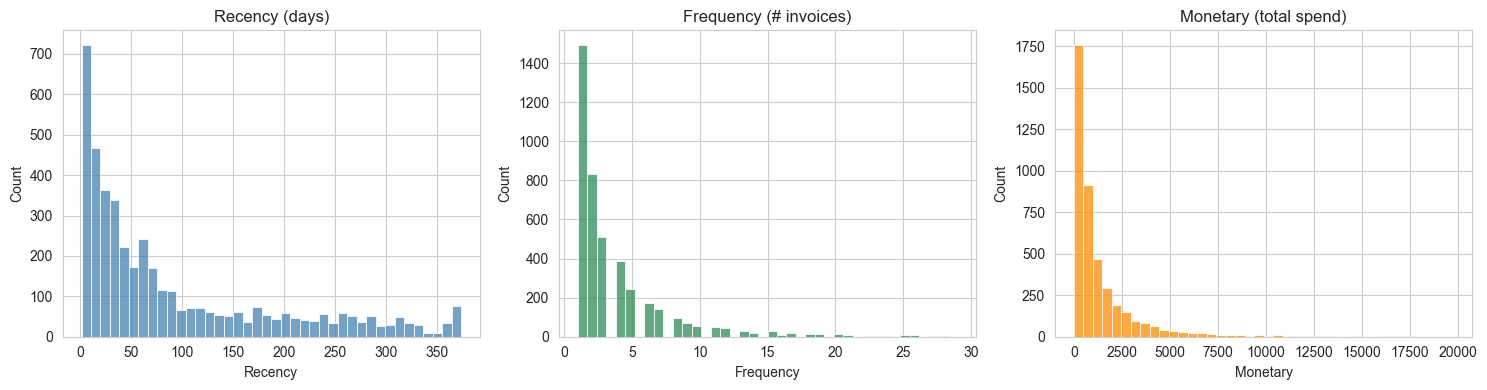

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
sns.histplot(rfm['Recency'], bins=40, ax=axes[0], color='steelblue')
axes[0].set_title('Recency (days)')
sns.histplot(rfm['Frequency'][rfm['Frequency'] < rfm['Frequency'].quantile(0.99)], bins=40, ax=axes[1], color='seagreen')
axes[1].set_title('Frequency (# invoices)')
sns.histplot(rfm['Monetary'][rfm['Monetary'] < rfm['Monetary'].quantile(0.99)], bins=40, ax=axes[2], color='darkorange')
axes[2].set_title('Monetary (total spend)')
plt.tight_layout()
plt.savefig('figs/rfm_dist.png', dpi=110)
plt.show()

### Standardize RFM values

In [13]:
X = rfm[['Recency', 'Frequency', 'Monetary']].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled[:5]

array([[ 2.33457414, -0.4250965 ,  8.36301037],
       [-0.90534032,  0.3544168 ,  0.2516989 ],
       [-0.17535959, -0.03533985, -0.02798783],
       [-0.73534481, -0.4250965 , -0.03240559],
       [ 2.17457836, -0.4250965 , -0.19081155]])

## Step 5: Choosing the Number of Clusters — Elbow Method & Silhouette Score

k=2: inertia=9014.6, silhouette=0.8958
k=3: inertia=5441.3, silhouette=0.5942
k=4: inertia=4096.3, silhouette=0.6162
k=5: inertia=3119.8, silhouette=0.6165
k=6: inertia=2473.8, silhouette=0.5983
k=7: inertia=2023.6, silhouette=0.5165
k=8: inertia=1717.0, silhouette=0.4859
k=9: inertia=1468.8, silhouette=0.4784
k=10: inertia=1281.0, silhouette=0.4792


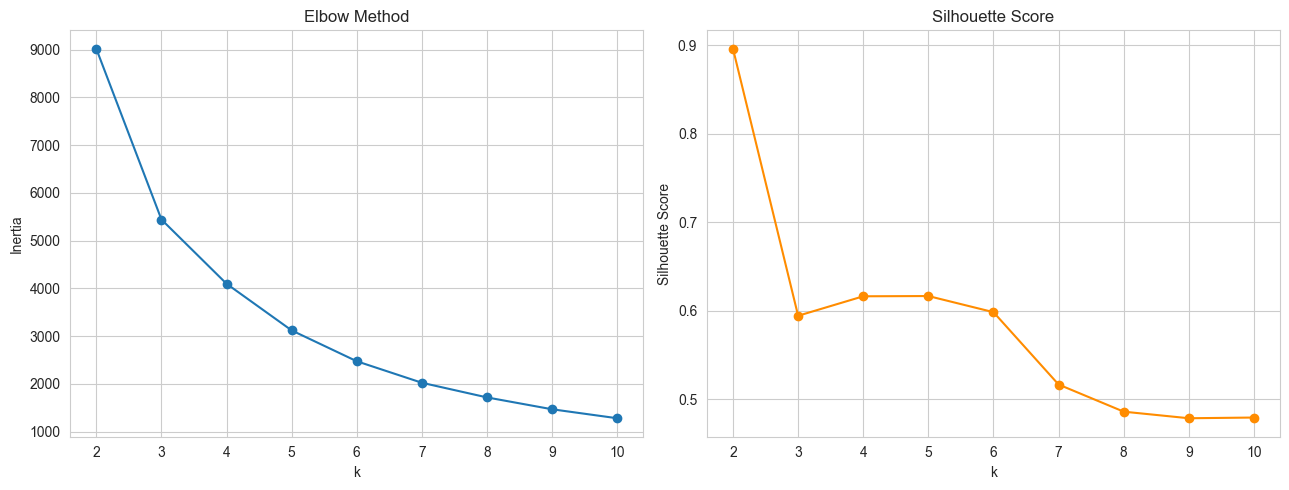

In [14]:
inertias, sil_scores = [], []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))
    print(f"k={k}: inertia={km.inertia_:.1f}, silhouette={sil_scores[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].plot(list(K_range), inertias, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')

axes[1].plot(list(K_range), sil_scores, marker='o', color='darkorange')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.savefig('figs/elbow_silhouette.png', dpi=110)
plt.show()

**Choice of k:** The business requirement calls for 4 interpretable segments
(*High-Value, Regular, Occasional, At-Risk*), and k=4 also sits at a strong point on the
silhouette curve (second-highest score, just behind the trivial k=2 split which fails to
separate mid-tier customers). We proceed with **k=4**.

## Step 6: Run KMeans Clustering (k=4)

In [15]:
best_k = 4
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(X_scaled)

cluster_profile = rfm.groupby('Cluster')[['Recency','Frequency','Monetary']].mean()
cluster_profile['Count'] = rfm.groupby('Cluster').size()
cluster_profile

,Recency,Frequency,Monetary,Count
Cluster,,,,
0,43.702685,3.682711,1353.625312,3054
1,248.075914,1.552015,478.848773,1067
2,7.384615,82.538462,127187.959231,13
3,15.500000,22.333333,12690.500392,204


### Label clusters from their RFM averages

We rank clusters on each RFM dimension (lower Recency is better; higher Frequency/Monetary is better),
sum the ranks, and map the best-to-worst clusters onto the four business segment labels.

In [16]:
profile = cluster_profile.copy()
profile['R_rank'] = profile['Recency'].rank(ascending=True)
profile['F_rank'] = profile['Frequency'].rank(ascending=False)
profile['M_rank'] = profile['Monetary'].rank(ascending=False)
profile['score'] = profile['R_rank'] + profile['F_rank'] + profile['M_rank']
profile = profile.sort_values('score')
print(profile)

segment_names = ['High-Value', 'Regular', 'Occasional', 'At-Risk']
labels_map = {cluster_id: segment_names[i] for i, cluster_id in enumerate(profile.index.tolist())}
print("\nCluster -> Segment mapping:", labels_map)

rfm['Segment'] = rfm['Cluster'].map(labels_map)
rfm['Segment'].value_counts()

            Recency  Frequency       Monetary  Count  R_rank  F_rank  M_rank  \
Cluster                                                                        
2          7.384615  82.538462  127187.959231     13     1.0     1.0     1.0   
3         15.500000  22.333333   12690.500392    204     2.0     2.0     2.0   
0         43.702685   3.682711    1353.625312   3054     3.0     3.0     3.0   
1        248.075914   1.552015     478.848773   1067     4.0     4.0     4.0   

         score  
Cluster         
2          3.0  
3          6.0  
0          9.0  
1         12.0  

Cluster -> Segment mapping: {2: 'High-Value', 3: 'Regular', 0: 'Occasional', 1: 'At-Risk'}


Segment
Occasional    3054
At-Risk       1067
Regular        204
High-Value      13
Name: count, dtype: int64

### Cluster scatter plot (RFM space)

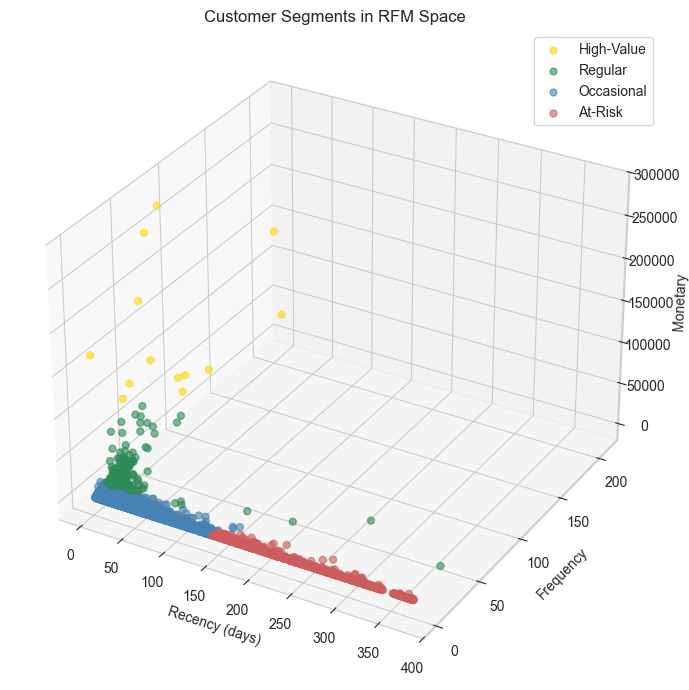

In [17]:
fig = plt.figure(figsize=(9,7))
ax = fig.add_subplot(111, projection='3d')
colors = {'High-Value':'gold', 'Regular':'seagreen', 'Occasional':'steelblue', 'At-Risk':'indianred'}
for seg, color in colors.items():
    sub = rfm[rfm['Segment'] == seg]
    ax.scatter(sub['Recency'], sub['Frequency'], sub['Monetary'], label=seg, c=color, alpha=0.6, s=25)
ax.set_xlabel('Recency (days)')
ax.set_ylabel('Frequency')
ax.set_zlabel('Monetary')
ax.set_title('Customer Segments in RFM Space')
ax.legend()
plt.tight_layout()
plt.savefig('figs/cluster_scatter_3d.png', dpi=110)
plt.show()

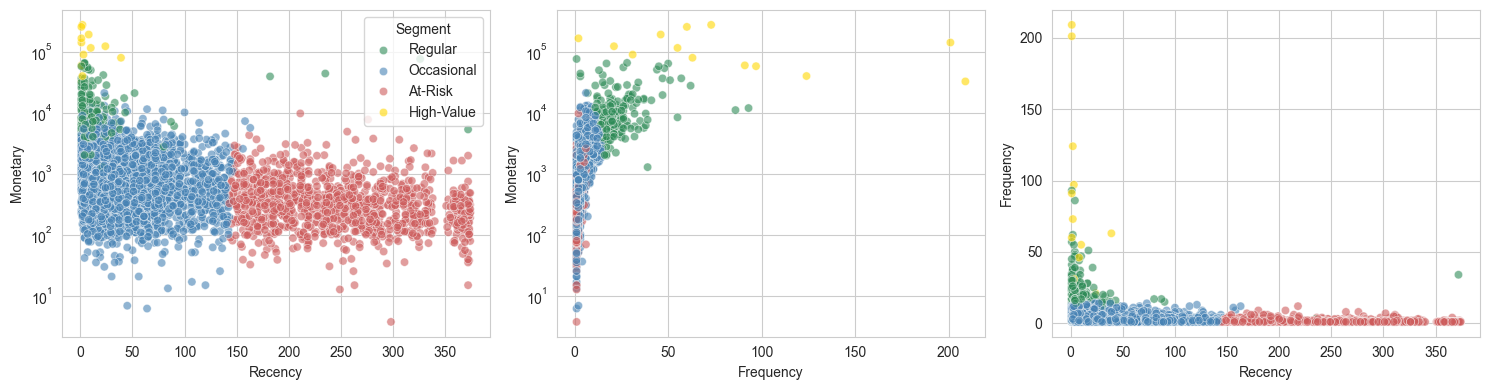

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Segment', palette=colors, ax=axes[0], alpha=0.6)
sns.scatterplot(data=rfm, x='Frequency', y='Monetary', hue='Segment', palette=colors, ax=axes[1], alpha=0.6, legend=False)
sns.scatterplot(data=rfm, x='Recency', y='Frequency', hue='Segment', palette=colors, ax=axes[2], alpha=0.6, legend=False)
axes[1].set_yscale('log'); axes[0].set_yscale('log')
plt.tight_layout()
plt.savefig('figs/cluster_scatter_2d.png', dpi=110)
plt.show()

### Save the clustering model for Streamlit

In [19]:
with open('kmeans_model.pkl', 'wb') as f:
    pickle.dump(kmeans, f)
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
with open('cluster_label_map.pkl', 'wb') as f:
    pickle.dump(labels_map, f)

rfm.to_csv('rfm_clustered.csv', index=False)
print("Saved kmeans_model.pkl, scaler.pkl, cluster_label_map.pkl, rfm_clustered.csv")

Saved kmeans_model.pkl, scaler.pkl, cluster_label_map.pkl, rfm_clustered.csv


## Step 7: Product Recommendation System (Item-Based Collaborative Filtering)

We build a **Customer × Product** purchase matrix (quantity purchased), transpose it to get a
**Product × Customer** matrix, and compute **cosine similarity** between products based on how
similarly customers purchase them.

In [20]:
pivot = df.pivot_table(index='CustomerID', columns='Description', values='Quantity',
                        aggfunc='sum', fill_value=0)
print("Customer-Product matrix shape:", pivot.shape)

item_matrix = pivot.T
similarity = cosine_similarity(item_matrix)
similarity_df = pd.DataFrame(similarity, index=item_matrix.index, columns=item_matrix.index)
print("Product similarity matrix shape:", similarity_df.shape)

Customer-Product matrix shape: (4338, 3639)
Product similarity matrix shape: (3639, 3639)


### Similarity heatmap (sample of top-selling products)

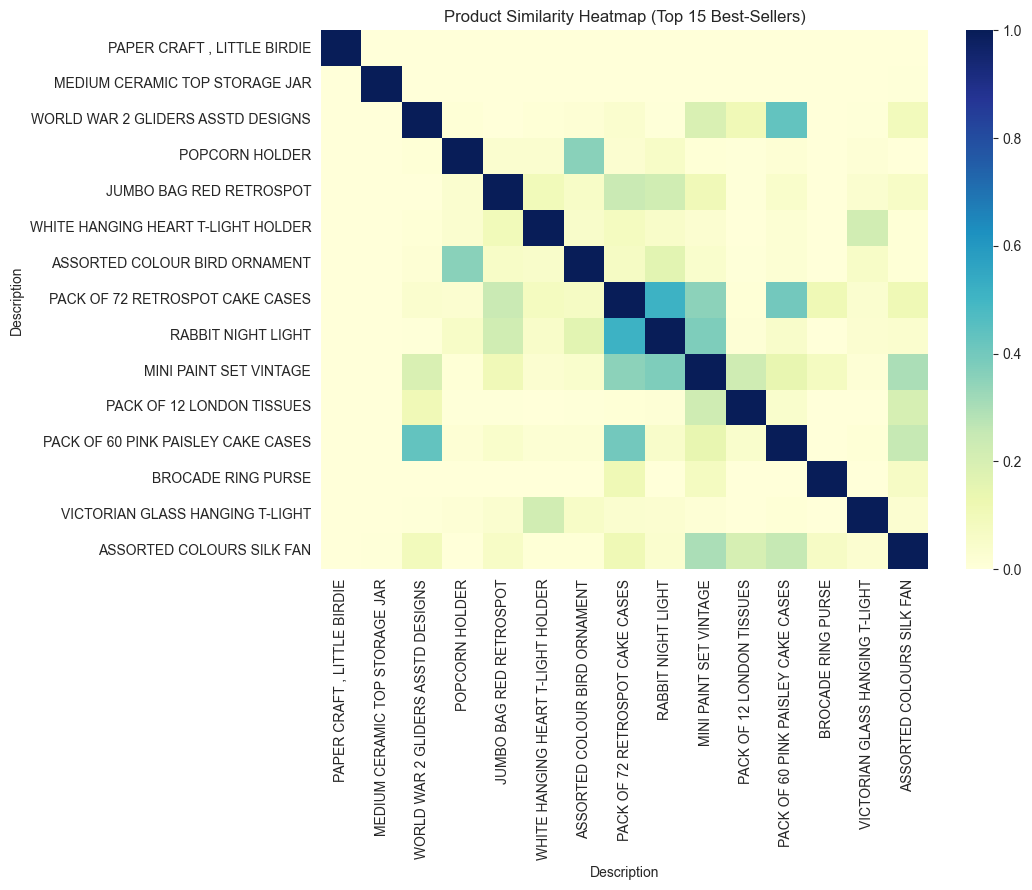

In [21]:
sample_products = top_products.index[:15]
plt.figure(figsize=(11,9))
sns.heatmap(similarity_df.loc[sample_products, sample_products], cmap='YlGnBu', annot=False)
plt.title('Product Similarity Heatmap (Top 15 Best-Sellers)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('figs/similarity_heatmap.png', dpi=110)
plt.show()

### Recommendation function

In [22]:
def recommend_products(product_name, top_n=5):
    if product_name not in similarity_df.columns:
        close = [p for p in similarity_df.columns if product_name.upper() in p.upper()]
        return f"Product not found. Did you mean: {close[:5]}" if close else "Product not found."
    sims = similarity_df[product_name].drop(product_name).sort_values(ascending=False)
    return list(sims.head(top_n).items())

recommend_products('WHITE HANGING HEART T-LIGHT HOLDER')

[('GIN + TONIC DIET METAL SIGN', 0.7494571401063287),
 ('RED HANGING HEART T-LIGHT HOLDER', 0.6587276017206894),
 ('WASHROOM METAL SIGN', 0.6438875312117198),
 ('LAUNDRY 15C METAL SIGN', 0.6424743002706346),
 ('GREEN VINTAGE SPOT BEAKER', 0.6309841521469737)]

### Save the recommendation artifacts for Streamlit

In [23]:
similarity_df.astype('float32').to_pickle('product_similarity.pkl')
product_list = sorted(similarity_df.columns.tolist())
with open('product_list.pkl', 'wb') as f:
    pickle.dump(product_list, f)
print(f"Saved product_similarity.pkl {similarity_df.shape} and product_list.pkl ({len(product_list)} products)")

Saved product_similarity.pkl (3639, 3639) and product_list.pkl (3639 products)


## Step 8: Model Evaluation Summary

| Metric | Value |
|---|---|
| Chosen k | 4 |
| Silhouette Score (k=4) | see printed output above (Step 5) |
| Segments | High-Value, Regular, Occasional, At-Risk |

The segmentation aligns with the required business interpretation:
- **High-Value**: very recent, highly frequent, top spenders — prioritize for loyalty/VIP programs.
- **Regular**: steady purchasers, moderate frequency/spend — upsell and cross-sell targets.
- **Occasional**: infrequent, lower spend — nurture with targeted promotions.
- **At-Risk**: long time since last purchase — target with win-back / retention campaigns.

## Conclusion

This notebook cleaned the raw online retail transactions, explored purchasing patterns,
engineered RFM features, segmented customers with KMeans (k=4, chosen via elbow + silhouette
analysis), and built an item-based collaborative filtering recommender using cosine similarity.
All trained artifacts (`kmeans_model.pkl`, `scaler.pkl`, `cluster_label_map.pkl`,
`product_similarity.pkl`, `product_list.pkl`) are saved for direct use by the companion
**Streamlit app** (`app.py`).